# Let's find objects, from a photo to a live camera

Shoutout to [D-FINE](https://github.com/Peterande/D-FINE) and the
[ExecuTorch object-detection demo](https://executorch.ai/playground/webgpu/#/demo/detect)
for the inspiration!

Find objects in a photo, then try your camera or a video. Adjust the confidence
slider and compare the original with its detections. Your photos and camera
frames stay in this browser.

The saved result below uses the sample photo. To try it yourself, choose CPU or
WebGPU with `DEVICE`, then select **Run → Run All Cells**. Your camera only starts
when you click **Start camera**.


In [1]:
import base64
import cv2
import json
import time
from pathlib import Path
from IPython.display import display

import numpy as np
import torch
from IPython.display import Image as DisplayImage
import sys
sys.path.insert(0, str(Path('dfine_models.zip').resolve()))

from dfine_models.nn.backbone.hgnetv2 import HGNetv2
from dfine_models.zoo.dfine.dfine import DFINE
from dfine_models.zoo.dfine.dfine_decoder import DFINETransformer
from dfine_models.zoo.dfine.hybrid_encoder import HybridEncoder


DEVICE = 'webgpu'
IMAGE_PATH = 'YellowLabradorLooking_new.jpg'
SCORE_THRESHOLD = 0.35
classes = json.loads(Path('coco_classes.json').read_text())
torch.autograd.set_multithreading_enabled(False)
torch.manual_seed(11)
print('PyTorch:', torch.__version__, '| device:', DEVICE)

print('OpenCV:', cv2.__version__)


PyTorch: 2.15.0a0 | device: webgpu
OpenCV: 5.0.0


## 1. Load the model and photo

We're using D-FINE Small's pretrained COCO weights with 640×640 inputs and FP32
values. The first run downloads about 40 MiB; later visits reuse the verified
browser cache. Start with the included photo or change `IMAGE_PATH` to your own.


In [3]:
from dfine_weights import load_checkpoint

async def load_model():
    checkpoint = await load_checkpoint()
    model = DFINE(
        backbone=HGNetv2(name='B0', return_idx=[1, 2, 3], freeze_at=-1,
                        freeze_norm=False, use_lab=True, pretrained=False),
        encoder=HybridEncoder(in_channels=[256, 512, 1024], hidden_dim=256,
                              depth_mult=0.34, expansion=0.5,
                              eval_spatial_size=[640, 640]),
        decoder=DFINETransformer(feat_channels=[256, 256, 256],
                                num_layers=3, num_points=[3, 6, 3],
                                eval_spatial_size=[640, 640]),
    ).eval()
    model.load_state_dict(checkpoint['model'], strict=True)
    del checkpoint
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    return model


model = None
model = await load_model()
print(f'Pretrained model ready: {sum(p.numel() for p in model.parameters()):,} parameters')

def prepare_frame(frame):
    height, width = frame.shape[:2]
    scale = min(640 / width, 640 / height)
    fitted_width = max(1, round(width * scale))
    fitted_height = max(1, round(height * scale))
    left, top = (640 - fitted_width) // 2, (640 - fitted_height) // 2
    canvas = np.full((640, 640, 3), 114, dtype=np.uint8)
    canvas[top:top + fitted_height, left:left + fitted_width] = cv2.resize(
        frame, (fitted_width, fitted_height), interpolation=cv2.INTER_LINEAR)
    rgb = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB).astype(np.float32) / 255
    tensor = torch.from_numpy(rgb.transpose(2, 0, 1).copy()).unsqueeze(0)
    return tensor, (left, top, width / fitted_width, height / fitted_height)

photo = cv2.imread(IMAGE_PATH)
if photo is None:
    raise FileNotFoundError(f'Could not read {IMAGE_PATH}')
values, transform = prepare_frame(photo)
print('Model input:', tuple(values.shape))


Loading pretrained weights (first download: 39.9 MiB)...
Weights verified and saved in the browser cache.
Pretrained model ready: 10,321,877 parameters
Model input: (1, 3, 640, 640)


## 2. Compile the model

The first call compiles for the selected device. Wait for **Model ready**,
then try the preview below.


In [4]:
if DEVICE == 'webgpu':
    from iree.runtime.webgpu import get_webgpu_device
    from iree.turbine.runtime.torch_device import TorchDevice
    gpu = TorchDevice(await get_webgpu_device(
        max_concurrent_operations=len(model.state_dict()) + 1), name='webgpu')
    backend = gpu.backend
else:
    import iree.turbine.runtime.torch_device
    gpu = None
    backend = 'turbine_cpu'

model = model.to(DEVICE)
device_input = values.to(DEVICE)
if gpu is not None:
    await gpu.synchronize()

compiled_model = torch.compile(model, backend=backend, fullgraph=True, dynamic=False)
print(f'Compiling for {DEVICE}...', flush=True)
with torch.inference_mode():
    answer = compiled_model(device_input)
outputs = {name: await gpu.to_cpu(answer[name]) if gpu is not None else answer[name].detach()
           for name in ('pred_logits', 'pred_boxes')}
if (tuple(outputs['pred_logits'].shape) != (1, 300, len(classes)) or
        tuple(outputs['pred_boxes'].shape) != (1, 300, 4) or
        not all(torch.isfinite(value).all() for value in outputs.values())):
    raise RuntimeError('The detector returned invalid outputs.')
print(f'Model ready on {DEVICE}.')


/lib/python3.14/site-packages/torch/utils/_filelock.py:4: UserWarning: only soft file lock is available
  from filelock import FileLock as base_FileLock


Compiling for webgpu...
Model ready on webgpu.


## 3. See the detections and try your camera

The original photo is on the left and its detections are on the right. Change
`SCORE_THRESHOLD` to show fewer or more detections in the saved-photo view.

Run all cells to open the live controls. Try the sample photo, upload a photo or
video, or click **Start camera** and allow access. Adjust **Confidence** and drag
the before/after slider. Click **Stop** when finished.


In [5]:
def draw_detections(frame, outputs, transform, threshold):
    frame = frame.copy()
    left, top, scale_x, scale_y = transform
    # D-FINE's postprocessor selects the top 300 query/class scores.
    scores, indices = outputs['pred_logits'][0].sigmoid().flatten().topk(300)
    labels, queries = indices % len(classes), indices // len(classes)
    boxes = outputs['pred_boxes'][0][queries]
    centres, sizes = boxes[:, :2], boxes[:, 2:]
    boxes = torch.cat((centres - sizes / 2, centres + sizes / 2), dim=-1) * 640
    palette = [(238, 117, 71), (79, 195, 255), (180, 80, 235),
               (90, 210, 85), (210, 140, 40), (100, 75, 240)]
    detections = []
    for score, label, box in zip(scores.tolist(), labels.tolist(), boxes.tolist()):
        if score < threshold:
            continue
        x1, y1, x2, y2 = box
        box = [max(0, min(frame.shape[1] - 1, (x1 - left) * scale_x)),
               max(0, min(frame.shape[0] - 1, (y1 - top) * scale_y)),
               max(0, min(frame.shape[1] - 1, (x2 - left) * scale_x)),
               max(0, min(frame.shape[0] - 1, (y2 - top) * scale_y))]
        if box[2] <= box[0] or box[3] <= box[1]:
            continue
        colour = palette[label % len(palette)]
        x1, y1, x2, y2 = [round(value) for value in box]
        cv2.rectangle(frame, (x1, y1), (x2, y2), colour, 2)
        caption = f'{classes[label]} {score:.0%}'
        (text_width, text_height), baseline = cv2.getTextSize(
            caption, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
        text_x = min(x1, max(0, frame.shape[1] - text_width - 8))
        text_y = max(text_height + 5, y1 - 5)
        cv2.rectangle(frame, (text_x, text_y - text_height - 5),
                      (text_x + text_width + 8, text_y + baseline + 2), colour, -1)
        cv2.putText(frame, caption, (text_x + 4, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (12, 18, 25), 1, cv2.LINE_AA)
        detections.append(dict(label=classes[label], score=round(score, 4),
                               box_xyxy=[round(value, 1) for value in box]))
    return frame, detections


async def process_frame(jpeg, threshold):
    started = time.perf_counter()
    threshold = float(threshold)
    if not 0 <= threshold <= 1:
        raise ValueError('Confidence must be between zero and one.')
    frame = cv2.imdecode(np.frombuffer(jpeg, dtype=np.uint8), cv2.IMREAD_COLOR)
    if frame is None or max(frame.shape[:2]) > 1024:
        raise ValueError('Expected a valid camera image no larger than 1024 pixels.')
    prepared, transform = prepare_frame(frame)
    prepared_at = time.perf_counter()
    device_input = prepared.to(DEVICE)
    with torch.inference_mode():
        prediction = compiled_model(device_input)
    if gpu is not None:
        actual = {name: await gpu.to_cpu(prediction[name])
                  for name in ('pred_logits', 'pred_boxes')}
    else:
        actual = {name: prediction[name].detach()
                  for name in ('pred_logits', 'pred_boxes')}
    model_at = time.perf_counter()
    if not all(torch.isfinite(value).all() for value in actual.values()):
        raise ValueError('The detector returned non-finite outputs.')

    frame, detections = draw_detections(frame, actual, transform, threshold)
    postprocessed_at = time.perf_counter()
    ok, encoded = cv2.imencode('.png', frame, [cv2.IMWRITE_PNG_COMPRESSION, 1])
    if not ok:
        raise RuntimeError('OpenCV could not encode the result.')
    png = base64.b64encode(encoded).decode()
    finished = time.perf_counter()
    timings = dict(prepare_ms=1000 * (prepared_at - started),
                   model_ms=1000 * (model_at - prepared_at),
                   postprocess_ms=1000 * (postprocessed_at - model_at),
                   encode_ms=1000 * (finished - postprocessed_at),
                   python_total_ms=1000 * (finished - started))
    return dict(png=png, threshold=threshold, detections=detections, timings=timings)


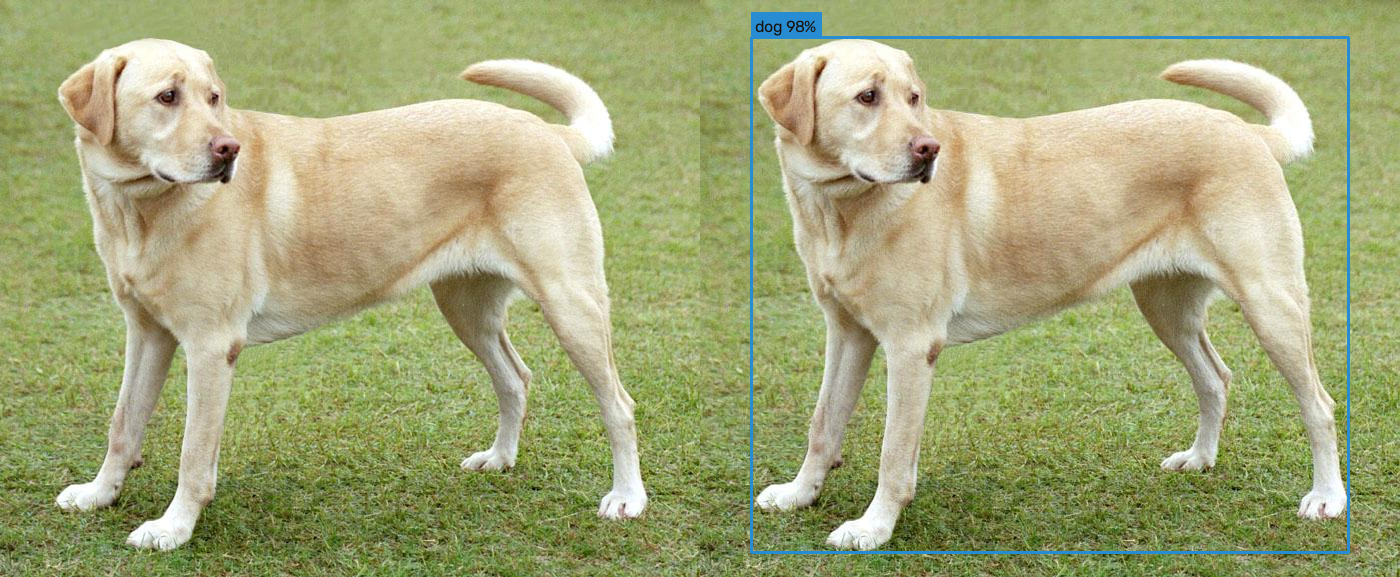

dog 98%


In [6]:
annotated, detections = draw_detections(photo, outputs, transform, SCORE_THRESHOLD)
ok, preview_png = cv2.imencode('.png', np.hstack((photo, annotated)))
if not ok:
    raise RuntimeError('Could not encode the detection preview.')
display(DisplayImage(data=preview_png.tobytes(), width=1000))
cv2.imwrite('dfine-detections.png', annotated)
print(', '.join(f"{item['label']} {item['score']:.0%}" for item in detections)
      or 'No objects above this confidence threshold.')

from live_detection import LiveDetection

if 'camera' in globals():
    await camera.close()
camera = LiveDetection(process_frame, sample=IMAGE_PATH, size=640, device=DEVICE)


To close the panel from Python, run `await camera.close()`. Re-running its cell closes the previous panel first.

Model and weights: [D-FINE](https://github.com/Peterande/D-FINE). Photo: [Yellow Labrador](https://commons.wikimedia.org/wiki/File:YellowLabradorLooking_new.jpg), Elf, with derivatives by Djmirko and FT2, CC BY-SA 3.0. Source details are in `sources.json`.
